**SetUp & Explore**

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import re
import random

#############################################################
# Carregar e Explorar
#############################################################
def load_data(file_path: str): #, nrows=582000):
    data = pd.read_csv(file_path, delimiter=',')#, nrows=nrows)

    return data

Dados prévia da Amostra

In [88]:
file_path = '..\Caso_TAP\TAP_Previa\Amostra 1(DEP LIS).csv'
data_Amostra = load_data(file_path)

print("\n### Informações do Dataset ###\n")
print(data_Amostra.info())

print("\n### Descrição ###\n")
print(data_Amostra.describe(include='all'))
print(data_Amostra.shape)
print(data_Amostra.head(1))


### Informações do Dataset ###

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Flight Nr       156 non-null    object
 1   Dep Airport     156 non-null    object
 2   COD GATE DEP    156 non-null    object
 3   STAND_DEP       156 non-null    object
 4   Arr Airport     156 non-null    object
 5   STAND_ARR       156 non-null    object
 6   SCHD_DEP_DT     156 non-null    object
 7   SCHD_DEP_TM     156 non-null    object
 8   ACT_DEP_DT      156 non-null    object
 9   ACT_DEP_TM      156 non-null    object
 10  SCHD_ARR_DT     156 non-null    object
 11  SCHD_ARR_TM     156 non-null    object
 12  ACT_ARR_DT      156 non-null    object
 13  ACT_ARR_TM      156 non-null    object
 14  Sales Capacity  156 non-null    int64 
 15  NR_PAX          156 non-null    int64 
dtypes: int64(2), object(14)
memory usage: 19.6+ KB
None

### Descriçã

<>:1: SyntaxWarning: invalid escape sequence '\C'
<>:1: SyntaxWarning: invalid escape sequence '\C'
C:\Users\joaoc\AppData\Local\Temp\ipykernel_17168\386520875.py:1: SyntaxWarning: invalid escape sequence '\C'
  file_path = '..\Caso_TAP\TAP_Previa\Amostra 1(DEP LIS).csv'


Dados do tempo de caminhada no hub do aeriporto

In [89]:
file_path = '..\Caso_TAP\TAP_Previa\Walking times HUB _ INFORM 1(Sheet1).csv'
data_Tempos_Caminnhada = load_data(file_path)

print("\n### Informações do Dataset ###\n")
print(data_Tempos_Caminnhada.info())

print("\n### Descrição ###\n")
print(data_Tempos_Caminnhada.describe(include='all'))
print(data_Tempos_Caminnhada.shape)
print(data_Tempos_Caminnhada.head(1))


### Informações do Dataset ###

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 6 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Traffic Network                    62 non-null     object 
 1   Start Traffic Network Point 1      62 non-null     object 
 2   Destination Traffic Network Point  62 non-null     object 
 3   Distance (in m)                    62 non-null     int64  
 4   Speed m/s                          62 non-null     float64
 5   Tempo minutos                      62 non-null     int64  
dtypes: float64(1), int64(2), object(3)
memory usage: 3.0+ KB
None

### Descrição ###

           Traffic Network Start Traffic Network Point 1  \
count                   62                            62   
unique                   4                            21   
top     SCHENGEN-NSCHENGEN                         22-23   
freq                    18

<>:1: SyntaxWarning: invalid escape sequence '\C'
<>:1: SyntaxWarning: invalid escape sequence '\C'
C:\Users\joaoc\AppData\Local\Temp\ipykernel_17168\3845097657.py:1: SyntaxWarning: invalid escape sequence '\C'
  file_path = '..\Caso_TAP\TAP_Previa\Walking times HUB _ INFORM 1(Sheet1).csv'


**Data Understanding**

**Dados Prévia**

*Temos dados de tempo de caminhada no hu  do aeroport ohumberto delgado, bem como uma amostra de chegadas*

Flight Nr,TP    -> 0009              \ numero do voo  

Dep Airport     -> LIS               \ aeroporto de partida

COD GATE DEP    -> 41A               \ código da porta de embarque

STAND_DEP       -> 803               \ ??

Arr Airport     -> NAT               \ Aeroporto de chegada

STAND_ARR       -> .                 \ ??

SCHD_DEP_DT     -> 10/11/2024 0:00   \ Data de Partida Agendada

SCHD_DEP_TM     -> 16:50             \ Tempo de Partida Agendado

ACT_DEP_DT      -> 10/11/2024 0:00   \ Data de Partida Agendada

ACT_DEP_TM      -> 18:27             \ Tempo de Partida Agendado

SCHD_ARR_DT     -> 10/12/2024 0:00   \ Data de Chegada Agendada

SCHD_ARR_TM     -> 0:20              \ Tempo de Chegada Agendado

ACT_ARR_DT      -> 10/12/2024 0:00   \ Data de Chegada Agendada

ACT_ARR_TM      -> 1:59              \ Tempo de Chegada Agendado

Sales Capacity  -> 168               \ Capacidade de Voo

NR_PAX -> 132                        \ Número de Passageiros

--------------------------/------------------------/---------------------/------------------

**Hub walk Time**

Traffic Network        ->   NSCHENGEN-SCHENGEN

Start Traffic          ->   14-16
Network Point 1 

Destination Traffic    ->   150
Network Point            

Distance (in m)        ->   7

Speed m/s              ->   1.1667

Tempo minutos          ->   2

--------------------------/------------------------/---------------------/------------------

**Actual DATA**

*Temos dados de chegadas, partifas e escalas no aeroporto humberto delgado entre otubro de 2023 e janeiro de 2025*

**Arrival List**

Flight Nr        ->     TP 0008

Dep Airport      ->     NAT

STAND_DEP        ->     .

Arr Airport      ->     LIS

COD GATE ARR     ->     N

STAND_ARR        ->     803

SCHD_DEP_DT      ->     2023-10-01 00:00:00

SCHD_DEP_TM      ->     01:15

ACT_DEP_DT       ->     2023-10-01 00:00:00

ACT_DEP_TM       ->     01:01

SCHD_ARR_DT      ->     2023-10-01 00:00:00

SCHD_ARR_TM      ->     08:25

ACT_ARR_DT       ->     2023-10-01 00:00:00

ACT_ARR_TM       ->     07:51

Sales Capacity   ->     168 

NR_PAX           ->     171

Soma             ->     -34

--------------------------/------------------------/---------------------/------------------

**Connection List**

Pairing          ->     TP 1243 PRG - IAD TP 0233
    
NATIO            ->     AFG
    
IN_FLT_NR        ->     TP 1243
    
IN_BOARD_PNT     ->     PRG
    
IN_OFF_PNT       ->     LIS
    
IN_STD           ->     2024-02-29 00:00:00
    
OUT_STD,         ->     2024-03-01 00:00:00
    
OUT_FLT_NR       ->     TP 0233
    
OUT_BOARD_PNT    ->     LIS
    
OUT_OFF_PNT      ->     IAD
    
MISCONN          ->     0
    
SUCCESS_TRANSF   ->     1
    
PAX TRANSF       ->     1
    
CONNECTIVITY     ->     "100,00%"

--------------------------/------------------------/---------------------/------------------

**Departure List**

Flight Nr         ->       TP 0009

Dep Airport       ->       LIS

COD GATE DEP      ->       45B

STAND_DEP         ->       414

Arr Airport       ->       NAT

STAND_ARR         ->       .

SCHD_DEP_DT       ->       2024-03-01 00:00:00

SCHD_DEP_TM       ->       17:10

ACT_DEP_DT        ->       2024-03-01 00:00:00

ACT_DEP_TM        ->       17:24

SCHD_ARR_DT       ->       2024-03-02 00:00:00

SCHD_ARR_TM       ->       00:45

ACT_ARR_DT        ->       2024-03-02 00:00:00

ACT_ARR_TM        ->       01:09

Sales Capacity    ->       168

NR_PAX            ->       128



**Causas mais frequentes de atrasos de voo**

Condições Meteriológicas adversas (Vento de proa)

Controlo de Trafego Aéreo num aeroporto congestionado congestionado

Voo de Conexão (Espera por passageiros de outro voo atrasado)

Número elevado de passageiros (Passager Seat Bottle neck)

Reparações na aeronave

**Identificação de Voos Atrasados ou cancelados:**

Canceled Flight = SCHD_DEP_DT != ACT_DEP_DT 

Delayed Flight  = SCHD_DEP_TM < ACT_DEP_TM 

**Precisamos definir o tempo antes da previsão do modelo**

Quais os principais componentes que influenciam?
Qual informação é que temos?
Quais são os dados mais importantes


In [90]:
import pandas as pd
import os
from glob import glob

# Definir o caminho para os arquivos CSV
caminho_dos_ARRLIS = '../Caso_TAP/TAP 3 1/ISCTE/ARRLIS'  
caminho_dos_CONNECTLIS = '../Caso_TAP/TAP 3 1/ISCTE/CONNECTLIS'  
caminho_dos_DEPLIS = '../Caso_TAP/TAP 3 1/ISCTE/DEPLIS'  

# Encontrar todos os arquivos CSV na pasta
arquivos_csv_ARRLIS = glob(os.path.join(caminho_dos_ARRLIS, "*.csv"))
arquivos_csv_CONNECTLIS = glob(os.path.join(caminho_dos_CONNECTLIS, "*.csv"))
arquivos_csv_DEPLIS = glob(os.path.join(caminho_dos_DEPLIS, "*.csv"))

# Criar uma lista para armazenar os DataFrames
dataframes_ARRLIS = []
dataframes_CONNECTLIS = []
dataframes_DEPLIS = []

# Ler e adicionar cada CSV à lista
for arquivo in arquivos_csv_ARRLIS:
    df = pd.read_csv(arquivo)  # Se houver separador diferente, use sep=";"
    dataframes_ARRLIS.append(df)

for arquivo in arquivos_csv_ARRLIS:
    df = pd.read_csv(arquivo)  # Se houver separador diferente, use sep=";"
    dataframes_CONNECTLIS.append(df)

for arquivo in arquivos_csv_ARRLIS:
    df = pd.read_csv(arquivo)  # Se houver separador diferente, use sep=";"
    dataframes_DEPLIS.append(df)
    
# Concatenar todos os DataFrames em um só
df_final_ARRLIS = pd.concat(dataframes_ARRLIS, ignore_index=True)
df_final_CONNECTLIS = pd.concat(dataframes_CONNECTLIS, ignore_index=True)
df_final_DEPLIS = pd.concat(dataframes_DEPLIS, ignore_index=True)

df_final = pd.concat([df_final_ARRLIS, df_final_CONNECTLIS, df_final_DEPLIS], ignore_index=True)

# Salvar o resultado em um novo CSV
df_final_ARRLIS.to_csv("dados_combinados_ARRLIS.csv", index=False)
df_final_CONNECTLIS.to_csv("dados_combinados_CONNECTLIS.csv", index=False)
df_final_DEPLIS.to_csv("dados_combinados_DEPLIS.csv", index=False)

df_final.to_csv("dados_completos.csv", index=False)


In [91]:
# Mostrar as primeiras linhas do dataframe final
print("\n Dados de chegada ao Aeroporto \n")
print(df_final_ARRLIS.head())
print("\n Dados de conexão no Aeroporto \n")
print(df_final_CONNECTLIS.head())
print("\n Dados de partida do Aeroporto \n")
print(df_final_DEPLIS.head())


 Dados de chegada ao Aeroporto 

  Flight Nr Dep Airport STAND_DEP Arr Airport COD GATE ARR STAND_ARR  \
0   TP 0008         NAT         .         LIS            N       803   
1   TP 0012         REC         .         LIS            N       404   
2   TP 0022         SSA         .         LIS           43       143   
3   TP 0036         FOR         .         LIS            N       602   
4   TP 0048         BEL         .         LIS            N       607   

           SCHD_DEP_DT SCHD_DEP_TM           ACT_DEP_DT ACT_DEP_TM  \
0  2023-10-01 00:00:00       01:15  2023-10-01 00:00:00      01:01   
1  2023-10-01 00:00:00       01:20  2023-10-01 00:00:00      01:45   
2  2023-10-01 00:00:00       01:55  2023-10-01 00:00:00      02:08   
3  2023-10-01 00:00:00       01:40  2023-10-01 00:00:00      01:37   
4  2023-10-01 00:00:00       02:35  2023-10-01 00:00:00      02:22   

           SCHD_ARR_DT SCHD_ARR_TM           ACT_ARR_DT ACT_ARR_TM  \
0  2023-10-01 00:00:00       08:25  2023-1

**DATA Understanding**

C:\Users\joaoc\AppData\Local\Temp\ipykernel_17168\3493586317.py:15: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['SCHD_DEP_DT'] = pd.to_datetime(df['SCHD_DEP_DT'] + ' ' + df['SCHD_DEP_TM'])
C:\Users\joaoc\AppData\Local\Temp\ipykernel_17168\3493586317.py:16: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['ACT_DEP_DT'] = pd.to_datetime(df['ACT_DEP_DT'] + ' ' + df['ACT_DEP_TM'])
C:\Users\joaoc\AppData\Local\Temp\ipykernel_17168\3493586317.py:17: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['SCHD_ARR_DT'] = pd.to_datetime(df['SCHD_ARR_DT'] + ' ' + df['SCHD_ARR_TM'])
C

       Atraso_Partida  Atraso_Chegada  Sales Capacity         NR_PAX
count   218712.000000   218712.000000   218712.000000  218712.000000
mean        20.447890       16.646508      170.258120     136.844522
std         34.700862       36.762822       53.942662      53.488391
min        -73.000000     -386.000000        0.000000       0.000000
25%          1.000000       -4.000000      132.000000      98.000000
50%         11.000000        9.000000      168.000000     132.000000
75%         29.000000       28.000000      204.000000     162.000000
max       1185.000000     1190.000000      376.000000     336.000000


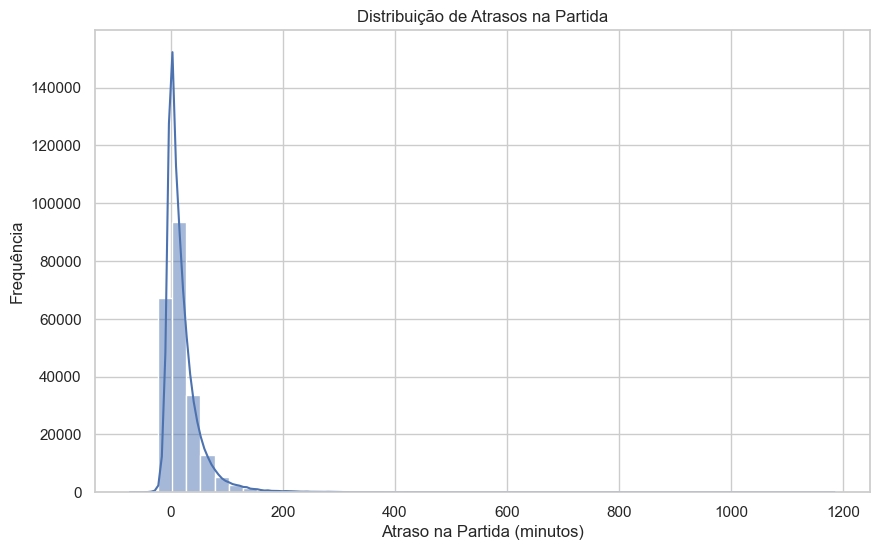

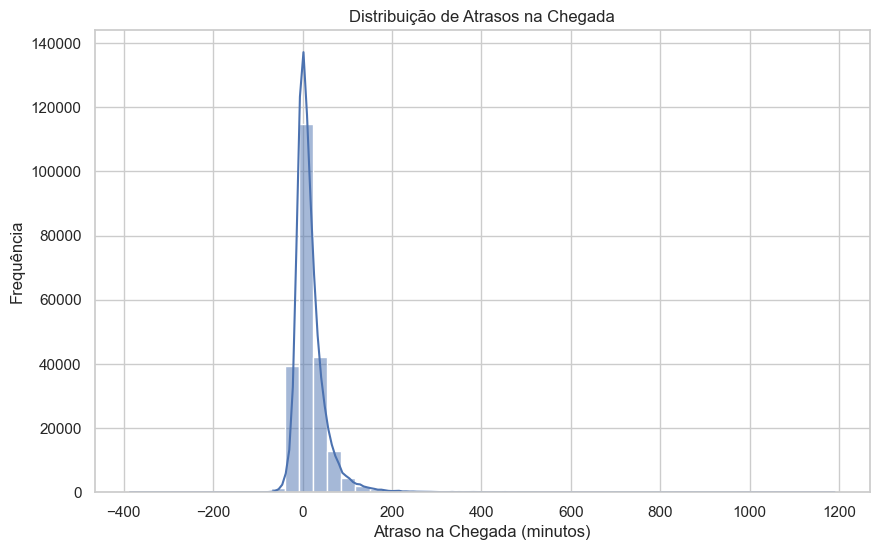

C:\Users\joaoc\AppData\Local\Temp\ipykernel_17168\3493586317.py:47: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='Dep Airport', y='Atraso_Partida', data=df, estimator=np.mean, ci=None)


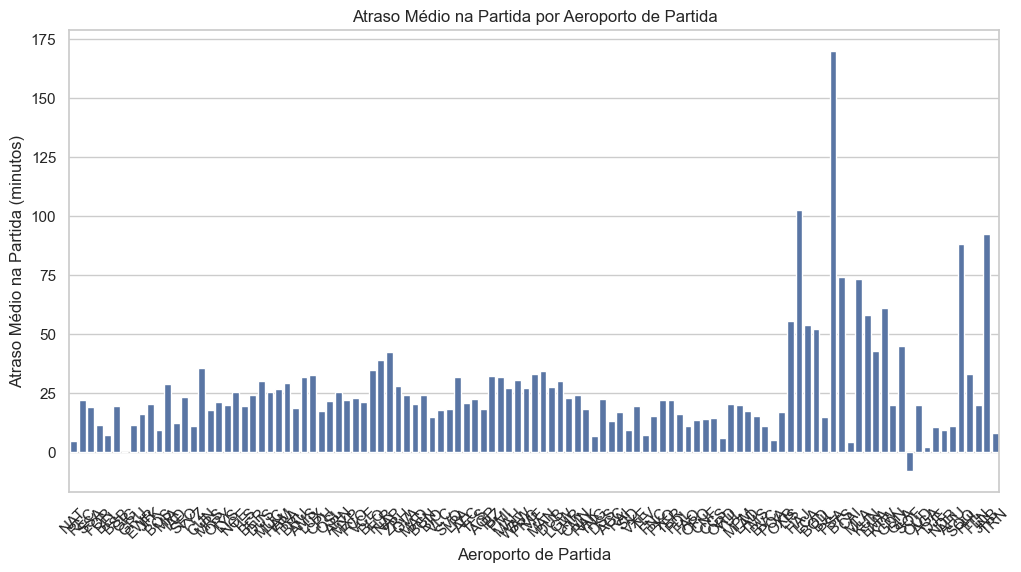

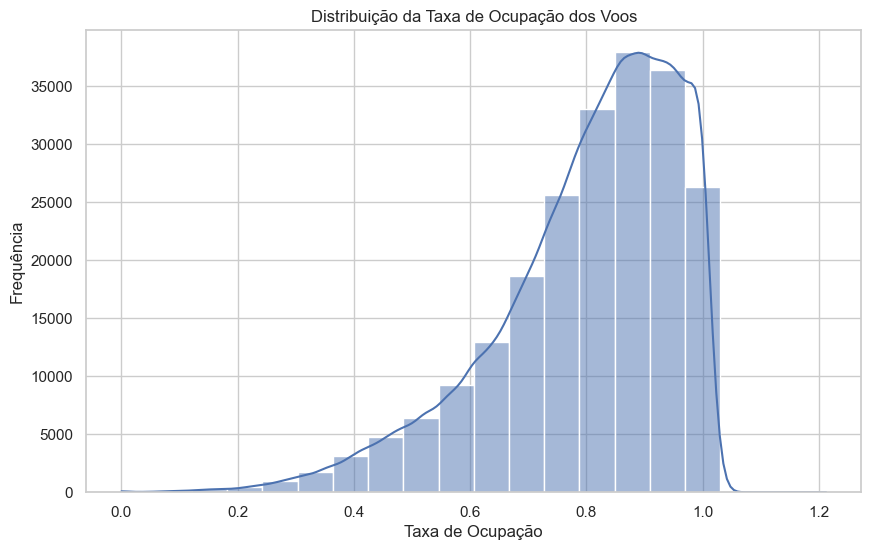

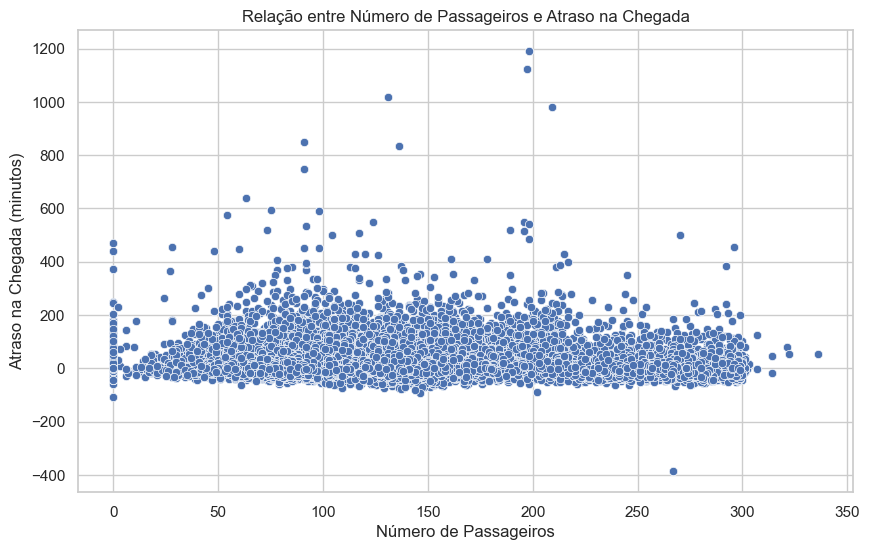

Porcentagem de dados faltantes por coluna:
Taxa_Ocupacao    0.314112
dtype: float64


In [92]:
# Configurações de exibição
pd.set_option('display.max_columns', None)
sns.set(style="whitegrid")

# 1. Carregar os dados
# Substitua 'seus_dados.csv' pelo caminho do seu arquivo de dados
df_ARRLIS = df_final_ARRLIS
df_CONNECTLIS = df_final_CONNECTLIS
df_DEPLIS = df_final_DEPLIS

df = df_final

# 2. Conversão de tipos de dados
# Convertendo colunas de data e hora para datetime
df['SCHD_DEP_DT'] = pd.to_datetime(df['SCHD_DEP_DT'] + ' ' + df['SCHD_DEP_TM'])
df['ACT_DEP_DT'] = pd.to_datetime(df['ACT_DEP_DT'] + ' ' + df['ACT_DEP_TM'])
df['SCHD_ARR_DT'] = pd.to_datetime(df['SCHD_ARR_DT'] + ' ' + df['SCHD_ARR_TM'])
df['ACT_ARR_DT'] = pd.to_datetime(df['ACT_ARR_DT'] + ' ' + df['ACT_ARR_TM'])

# 3. Cálculo de atrasos
df['Atraso_Partida'] = (df['ACT_DEP_DT'] - df['SCHD_DEP_DT']).dt.total_seconds() / 60.0
df['Atraso_Chegada'] = (df['ACT_ARR_DT'] - df['SCHD_ARR_DT']).dt.total_seconds() / 60.0

# 4. Estatísticas descritivas
print(df[['Atraso_Partida', 'Atraso_Chegada', 'Sales Capacity', 'NR_PAX']].describe())

# 5. Visualizações

# 5.1. Distribuição de atrasos na partida
plt.figure(figsize=(10, 6))
sns.histplot(df['Atraso_Partida'].dropna(), bins=50, kde=True)
plt.title('Distribuição de Atrasos na Partida')
plt.xlabel('Atraso na Partida (minutos)')
plt.ylabel('Frequência')
plt.show()

# 5.2. Distribuição de atrasos na chegada
plt.figure(figsize=(10, 6))
sns.histplot(df['Atraso_Chegada'].dropna(), bins=50, kde=True)
plt.title('Distribuição de Atrasos na Chegada')
plt.xlabel('Atraso na Chegada (minutos)')
plt.ylabel('Frequência')
plt.show()

# 5.3. Atrasos médios por aeroporto de partida
plt.figure(figsize=(12, 6))
sns.barplot(x='Dep Airport', y='Atraso_Partida', data=df, estimator=np.mean, ci=None)
plt.title('Atraso Médio na Partida por Aeroporto de Partida')
plt.xlabel('Aeroporto de Partida')
plt.ylabel('Atraso Médio na Partida (minutos)')
plt.xticks(rotation=45)
plt.show()

# 5.5. Taxa de ocupação
df['Taxa_Ocupacao'] = df['NR_PAX'] / df['Sales Capacity']
plt.figure(figsize=(10, 6))
sns.histplot(df['Taxa_Ocupacao'].dropna(), bins=20, kde=True)
plt.title('Distribuição da Taxa de Ocupação dos Voos')
plt.xlabel('Taxa de Ocupação')
plt.ylabel('Frequência')
plt.show()

# 6. Análise de conexões (se aplicável)
if 'MISCONN' in df.columns:
    # Taxa de sucesso de conexões
    taxa_sucesso = df['MISCONN'].count(1) / df['MISCONN'].sum()
    print(f'Taxa de Sucesso de Conexões: {taxa_sucesso:.2%}')

    # Análise de conexões perdidas
    misconn_df = df[df['MISCONN'] == 1]
    plt.figure(figsize=(12, 6))
    sns.countplot(x='IN_BOARD_PNT', data=misconn_df)
    plt.title('Número de Conexões Perdidas por Aeroporto de Origem')
    plt.xlabel('Aeroporto de Origem')
    plt.ylabel('Número de Conexões Perdidas')
    plt.xticks(rotation=45)
    plt.show()

# Scatter plot entre número de passageiros e atraso na chegada
plt.figure(figsize=(10, 6))
sns.scatterplot(x='NR_PAX', y='Atraso_Chegada', data=dados_chegada)
plt.title('Relação entre Número de Passageiros e Atraso na Chegada')
plt.xlabel('Número de Passageiros')
plt.ylabel('Atraso na Chegada (minutos)')
plt.show()

# 7. Tratamento de dados faltantes
# Exibir a porcentagem de dados faltantes por coluna
missing_data = df.isnull().mean() * 100
print('Porcentagem de dados faltantes por coluna:')
print(missing_data[missing_data > 0])